# Remove or transform extreme outliers by implementing multiple outlier-handling strategies,
# such as Winsorization and log transformations, 
# and justify the chosen method with a comparative analysis.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("heart.csv")

df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


# Outliers count

In [4]:
cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, "Outliers:", count)

Age Outliers: 0
RestingBP Outliers: 28
Cholesterol Outliers: 183
MaxHR Outliers: 2
Oldpeak Outliers: 16


# Original data in Boxplo

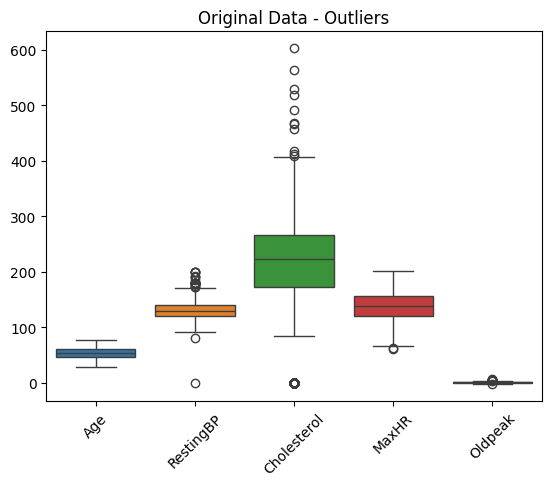

In [5]:
sns.boxplot(data=df[cols])
plt.title("Original Data - Outliers")
plt.xticks(rotation=45)
plt.show()

# Winsorization

In [7]:
winsor = df.copy()

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    winsor[col] = df[col].clip(lower, upper)

print("Winsorization completed!")
winsor.head()

Winsorization completed!


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195.0,0,Normal,122,N,0.0,Up,0


# Log Transformation

In [8]:
log_data = df.copy()

for col in cols:
    log_data[col] = np.sign(df[col]) * np.log1p(
        np.abs(df[col])
    )

print("Log Transformation completed!")
log_data.head()

Log Transformation completed!


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,3.713572,M,ATA,4.948760,5.669881,0,Normal,5.153292,N,0.000000,Up,0
1,3.912023,F,NAP,5.081404,5.198497,0,Normal,5.056246,N,0.693147,Flat,1
2,3.637586,M,ATA,4.875197,5.648974,0,ST,4.595120,N,0.000000,Up,0
3,3.891820,F,ASY,4.934474,5.370638,0,Normal,4.691348,Y,0.916291,Flat,1
4,4.007333,M,NAP,5.017280,5.278115,0,Normal,4.812184,N,0.000000,Up,0


# graphs

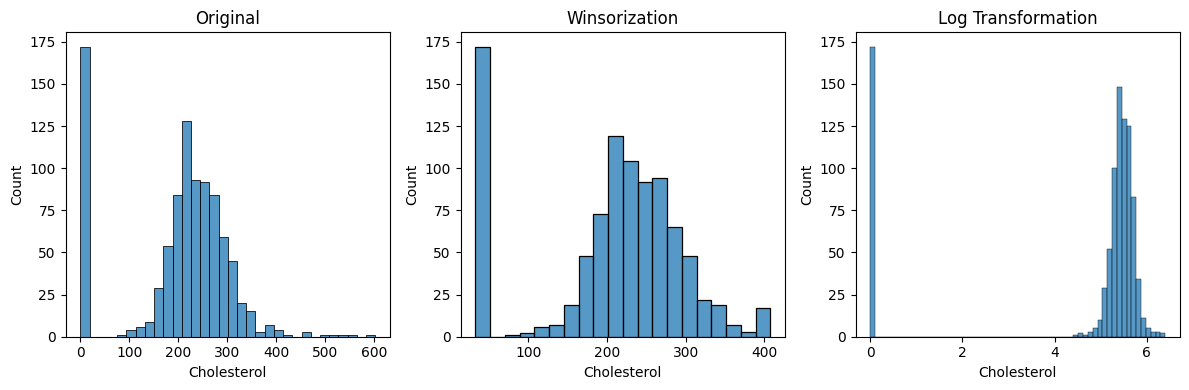

In [9]:
col = "Cholesterol"

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.histplot(df[col])
plt.title("Original")

plt.subplot(1, 3, 2)
sns.histplot(winsor[col])
plt.title("Winsorization")

plt.subplot(1, 3, 3)
sns.histplot(log_data[col])
plt.title("Log Transformation")

plt.tight_layout()
plt.show()

# Comparison table

In [10]:
comparison = pd.DataFrame({
    "Method": ["Original", "Winsorization", "Log Transformation"],
    "Cholesterol Mean": [
        df["Cholesterol"].mean(),
        winsor["Cholesterol"].mean(),
        log_data["Cholesterol"].mean()
    ],
    "Cholesterol Std": [
        df["Cholesterol"].std(),
        winsor["Cholesterol"].std(),
        log_data["Cholesterol"].std()
    ],
    "Cholesterol Skewness": [
        df["Cholesterol"].skew(),
        winsor["Cholesterol"].skew(),
        log_data["Cholesterol"].skew()
    ]
})

display(comparison.round(2))

,Method,Cholesterol Mean,Cholesterol Std,Cholesterol Skewness
0,Original,198.80,109.38,-0.61
1,Winsorization,203.99,95.92,-0.61
2,Log Transformation,4.45,2.15,-1.57


# Conclusion

In [11]:
print("Original Data: Extreme values present hoi shake che.")
print("Winsorization: Extreme values ne limit ma cap kare che.")
print("Log Transformation: Values ni scale ane skewness reduce kari shake che.")
print("Comparison table ane graphs parthi suitable method select karvi.")

Original Data: Extreme values present hoi shake che.
Winsorization: Extreme values ne limit ma cap kare che.
Log Transformation: Values ni scale ane skewness reduce kari shake che.
Comparison table ane graphs parthi suitable method select karvi.
